# Census Income Prediction (Adult)

**Dataset:** UCI Adult / Census Income — 48,842 people from the 1994 US Census with a full record (30,162 after dropping rows with unknown values). **Task:** predict whether a person earns over $50K/year from demographics and work features.

A fairness note is built into the analysis: features like sex and race are in the data because the census collected them — a real deployment would need a bias audit before use.

In [1]:
import io, urllib.request, zipfile
import pandas as pd

def get(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=90) as r: return r.read()

zf = zipfile.ZipFile(io.BytesIO(get('https://archive.ics.uci.edu/static/public/2/adult.zip')))
name = [n for n in zf.namelist() if n.endswith('adult.data')][0]
cols = ['age','workclass','fnlwgt','education','education-num','marital-status','occupation','relationship','race','sex','capital-gain','capital-loss','hours-per-week','native-country','income']
d = pd.read_csv(io.BytesIO(zf.read(name)), header=None, names=cols, skipinitialspace=True, na_values='?').dropna()
print(d.shape)
d.head()

(30162, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [2]:
y = (d['income'].str.contains('>50K')).astype(int)
X = pd.get_dummies(d.drop(columns=['income', 'fnlwgt']), drop_first=True)
print('Features:', X.shape[1], '| >50K share:', round(100*y.mean(), 1), '%')

Features: 95 | >50K share: 24.9 %


Majority baseline: 0.7511


Random Forest accuracy: 0.8434
Logistic Regression accuracy: 0.8466


              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90      5664
        >50K       0.71      0.62      0.66      1877

    accuracy                           0.84      7541
   macro avg       0.80      0.77      0.78      7541
weighted avg       0.84      0.84      0.84      7541



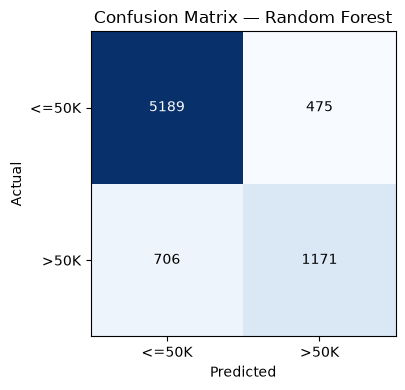

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr, ytr)
sc = StandardScaler().fit(Xtr)
lr = LogisticRegression(max_iter=1000).fit(sc.transform(Xtr), ytr)
print('Majority baseline:', round(float((yte == 0).mean()), 4))
print('Random Forest accuracy:', round(accuracy_score(yte, rf.predict(Xte)), 4))
print('Logistic Regression accuracy:', round(accuracy_score(yte, lr.predict(sc.transform(Xte))), 4))
print(classification_report(yte, rf.predict(Xte), target_names=['<=50K', '>50K']))
cm = confusion_matrix(yte, rf.predict(Xte))
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1], ['<=50K', '>50K']); ax.set_yticks([0, 1], ['<=50K', '>50K'])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion Matrix — Random Forest')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.tight_layout(); fig.savefig('confusion_matrix.png', dpi=110); plt.show()

## What I learned
- Education-num, marital status, occupation and capital gains carry most of the signal.
- The gap between the forest and logistic regression is small — most of the structure is roughly additive.
- A model like this must never be deployed for real decisions about people without a fairness audit: census features include protected attributes.